# Peramalan Deret Waktu (Forecasting) Tingkat Pengangguran Terbuka Indonesia (2017–2024 → 2030)
### ACTION 2026 — Annual Competition of Data Science (UNESA)
**Subtema:** *“Turning Insight into Opportunity: Analisis Pengangguran Terbuka untuk Pemerataan Kesempatan Kerja”*  
**Unit Analisis:** Deret Waktu Tahunan TPT Nasional BPS Sakernas (2017–2024)  
**Tujuan:** Menguji akurasi model peramalan melalui cross-validation multi-horizon dan memproyeksikan TPT Indonesia menuju tahun 2030 (Era RPJMN & SDGs 8).

---


## 0. Setup Lingkungan & Dependensi


In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RS = 42
np.random.seed(RS)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 9})

HIJAU = '#2F7D6E'
BATA  = '#C0392B'
PASIR = '#D9B26F'
ABU   = '#8896A0'

DATA_DIR = '../data/clean'
print("Setup selesai. Siap menjalankan pemodelan peramalan.")


Setup selesai. Siap menjalankan pemodelan peramalan.


## 1. Memuat Deret Waktu Historis TPT Nasional BPS (2017–2024)


In [2]:
panel_hist = pd.read_csv(f'{DATA_DIR}/panel_tpt_provinsi_2017_2024.csv')
idn_row = panel_hist[panel_hist["Provinsi"] == "Indonesia"].iloc[0]

years = np.array([2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])
y_series = np.array([idn_row[f"TPT_{yr}"] for yr in years])

df_ts = pd.DataFrame({"Tahun": years, "TPT_Nasional": y_series})
display(df_ts)


,Tahun,TPT_Nasional
0,2017,5.50
1,2018,5.30
2,2019,5.23
3,2020,7.07
4,2021,6.49
5,2022,5.86
6,2023,5.32
7,2024,4.91


## 2. Uji Kelayakan Ramalan & Evaluasi Cross-Validation Multi-Horizon


Model Terbaik Per Horizon:


,Horizon,Model_Terpilih,MASE,MAPE (%),RMSE
0,h = 1 (2025),Naive (Baseline),0.885,9.55,0.546
1,h = 2 (2026),Holt Exponential Smoothing,1.156,13.13,0.793
2,h = 3 (2027),Rata-Rata Bergerak (MA-3),1.059,12.03,0.772


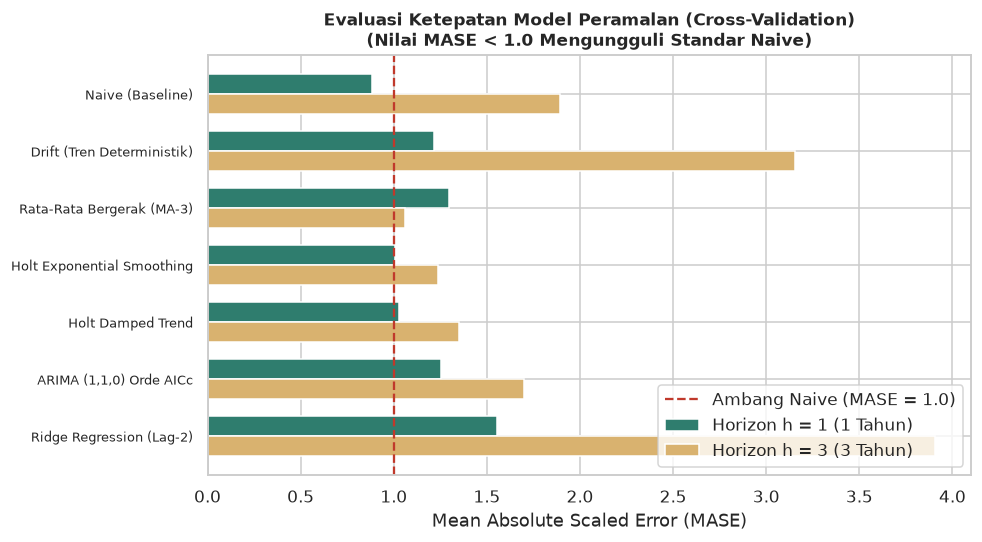

In [3]:
df_cv = pd.read_csv(f'{DATA_DIR}/uji_kelayakan_ramalan_tpt.csv')
df_best = pd.read_csv(f'{DATA_DIR}/aturan_per_horizon_tpt.csv')

print("Model Terbaik Per Horizon:")
display(df_best)

fig, ax = plt.subplots(figsize=(9, 5))
sub_h1 = df_cv[df_cv["Horizon"] == "h = 1"].set_index("Model")["MASE"]
sub_h3 = df_cv[df_cv["Horizon"] == "h = 3"].set_index("Model")["MASE"]

y_pos = np.arange(len(sub_h1))
bar_h = 0.35
ax.barh(y_pos - bar_h/2, sub_h1.values, bar_h, label="Horizon h = 1 (1 Tahun)", color=HIJAU)
ax.barh(y_pos + bar_h/2, sub_h3.values, bar_h, label="Horizon h = 3 (3 Tahun)", color=PASIR)
ax.axvline(1.0, color=BATA, linestyle="--", linewidth=1.5, label="Ambang Naive (MASE = 1.0)")
ax.set_yticks(y_pos)
ax.set_yticklabels(sub_h1.index, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("Mean Absolute Scaled Error (MASE)")
ax.set_title("Evaluasi Ketepatan Model Peramalan (Cross-Validation)\n(Nilai MASE < 1.0 Mengungguli Standar Naive)", fontsize=11, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 3. Proyeksi Jangka Menengah Menuju 2030 (Fan Chart Probabilitas)


,Tahun,Proyeksi_TPT,Lower_80,Upper_80,Lower_95,Upper_95
0,2025,5.05,3.93,6.16,3.34,6.76
1,2026,4.96,3.38,6.54,2.54,7.38
2,2027,4.88,2.94,6.81,1.91,7.84
3,2028,4.80,2.57,7.04,1.50,8.23
4,2029,4.74,2.24,7.24,1.50,8.56
5,2030,4.68,2.00,7.41,1.50,8.87


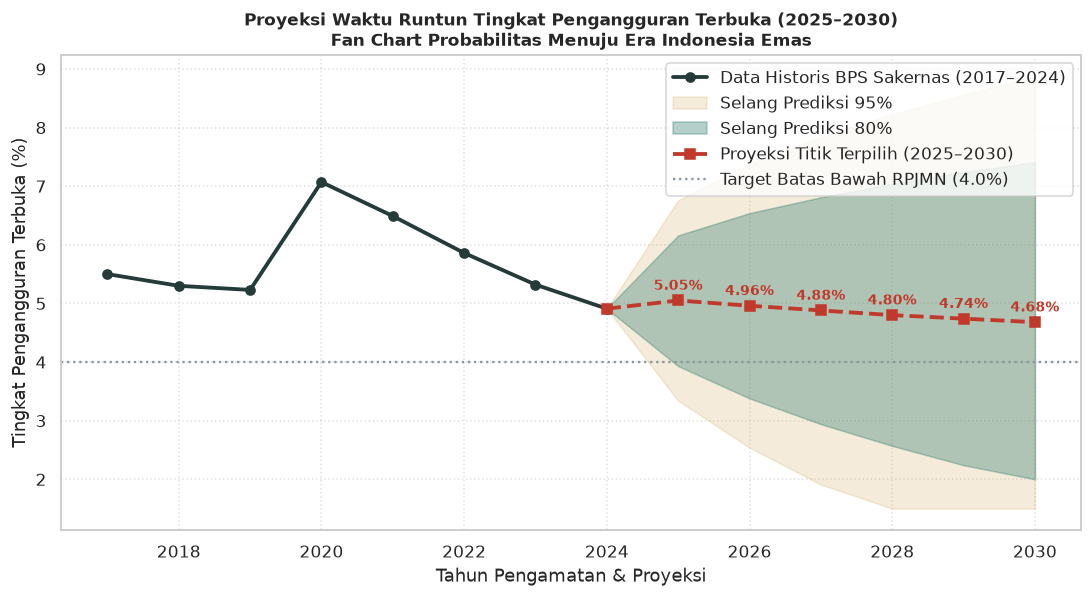

In [4]:
df_proj = pd.read_csv(f'{DATA_DIR}/proyeksi_tpt_indonesia_2025_2030.csv')
display(df_proj)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(years, y_series, marker="o", color='#243B3A', linewidth=2.5, label="Data Historis BPS Sakernas (2017–2024)")

future_years = df_proj["Tahun"].values
proj_point = df_proj["Proyeksi_TPT"].values

trans_years = np.concatenate([[years[-1]], future_years])
trans_proj = np.concatenate([[y_series[-1]], proj_point])
trans_l80 = np.concatenate([[y_series[-1]], df_proj["Lower_80"].values])
trans_u80 = np.concatenate([[y_series[-1]], df_proj["Upper_80"].values])
trans_l95 = np.concatenate([[y_series[-1]], df_proj["Lower_95"].values])
trans_u95 = np.concatenate([[y_series[-1]], df_proj["Upper_95"].values])

ax.fill_between(trans_years, trans_l95, trans_u95, color=PASIR, alpha=0.25, label="Selang Prediksi 95%")
ax.fill_between(trans_years, trans_l80, trans_u80, color=HIJAU, alpha=0.35, label="Selang Prediksi 80%")
ax.plot(trans_years, trans_proj, marker="s", color=BATA, linewidth=2.5, linestyle="--", label="Proyeksi Titik Terpilih (2025–2030)")
ax.axhline(4.0, color=ABU, linestyle=":", linewidth=1.5, label="Target Batas Bawah RPJMN (4.0%)")

ax.set_title("Proyeksi Waktu Runtun Tingkat Pengangguran Terbuka (2025–2030)\nFan Chart Probabilitas Menuju Era Indonesia Emas", fontsize=11, fontweight="bold")
ax.set_xlabel("Tahun Pengamatan & Proyeksi")
ax.set_ylabel("Tingkat Pengangguran Terbuka (%)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right")

for yr, val in zip(future_years, proj_point):
    ax.annotate(f"{val:.2f}%", (yr, val), textcoords="offset points", xytext=(0, 7), ha='center', fontweight="bold", color=BATA)

plt.tight_layout()
plt.show()
